# Imports

In [46]:
import pandas as pd 
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from Pyfrontier.frontier_model import EnvelopDEA as fm


# Load Dataset

In [3]:
df = pd.read_csv('dataset/EDA_QN.csv')
df

,Evento_ID,Custo_Estrutura,Custo_Atracoes,Publico,Custo_Equipe,Insumos,Ticket_Medio_Bar,Receita_Bar,Ticket_Medio_Bilheteria,Receita_Bilheria,Lucro
0,Q1,"11703,25",2850,451,2910,"13484,55","60,51",27288,"15,43","6960,2","3300,41"
1,Q2,"12727,83",3150,554,3285,"15514,94","57,45",31825,"20,37","11283,3","8430,53"
2,Q3,"13313,27",3150,623,3000,"14545,58","48,53",30236,"13,93","8675,4","5048,55"
3,Q4,"15192,83",3150,997,3610,"22863,19","59,61",59432,"26,15","26068,3","40015,78"
4,Q5,"28424,9",3200,1654,7134,"40412,98","55,48",91765,"33,66","55666,5","63744,62"
5,Q6,"13144,89",2650,743,3090,"15998,58","57,93",43041,"23,63","17557,55","24978,08"
6,Q7,"18922,11",3350,873,4348,"18729,14","50,20",43824,"27,36","23886,15","20989,9"
7,Q8,"18204,42",3350,848,3954,"17956,57","46,60",39518,"22,85","19380,75","14514,27"
8,Q9,"12357,59",4550,512,2820,"11457,69","41,21","21099,01","17,15","8780,75","-1165,01"
9,Q10,"29457,58","5367,96",1659,6760,"37321,86","61,85",102616,"35,19","58385,6","77225,2"


# Organizando Grupos

In [ ]:
df1 = df.copy()

#ordenando dataset por numero de publico
df1 = df1.sort_values(by='Publico', ascending=True)
df1

,Evento_ID,Custo_Estrutura,Custo_Atracoes,Publico,Custo_Equipe,Insumos,Ticket_Medio_Bar,Receita_Bar,Ticket_Medio_Bilheteria,Receita_Bilheria,Lucro
0,Q1,"11703,25",2850,451,2910,"13484,55","60,51",27288,"15,43","6960,2","3300,41"
8,Q9,"12357,59",4550,512,2820,"11457,69","41,21","21099,01","17,15","8780,75","-1165,01"
18,Q19,"12248,54",2850,531,3410,"9751,06","43,32",23001,"16,23","8618,25","4253,16"
1,Q2,"12727,83",3150,554,3285,"15514,94","57,45",31825,"20,37","11283,3","8430,53"
2,Q3,"13313,27",3150,623,3000,"14545,58","48,53",30236,"13,93","8675,4","5048,55"
10,Q11,"14014,77",4750,713,4309,"19118,09","61,55",43885,"21,05","15006,1","16220,24"
12,Q13,15541,3870,738,3835,"23380,73","71,31","52627,5","25,10",18527,"24232,27"
5,Q6,"13144,89",2650,743,3090,"15998,58","57,93",43041,"23,63","17557,55","24978,08"
17,Q18,"16858,59",3526,745,4267,"20034,88","50,01",37259,"24,95","18584,75","11388,79"
7,Q8,"18204,42",3350,848,3954,"17956,57","46,60",39518,"22,85","19380,75","14514,27"


In [25]:
#trocando os numeros em str para float
colunas = df1.columns.to_list()

#trocou virgulas por ponto passa para flaot
for col in colunas:
    if col != 'Evento_ID':
        df1[col] = df1[col].replace(',', '.', regex=True).astype(float)
        
df1.head(5)

,Evento_ID,Custo_Estrutura,Custo_Atracoes,Publico,Custo_Equipe,Insumos,Ticket_Medio_Bar,Receita_Bar,Ticket_Medio_Bilheteria,Receita_Bilheria,Lucro
0,Q1,11703.25,2850.0,451.0,2910.0,13484.55,60.51,27288.00,15.43,6960.20,3300.41
8,Q9,12357.59,4550.0,512.0,2820.0,11457.69,41.21,21099.01,17.15,8780.75,-1165.01
18,Q19,12248.54,2850.0,531.0,3410.0,9751.06,43.32,23001.00,16.23,8618.25,4253.16
1,Q2,12727.83,3150.0,554.0,3285.0,15514.94,57.45,31825.00,20.37,11283.30,8430.53
2,Q3,13313.27,3150.0,623.0,3000.0,14545.58,48.53,30236.00,13.93,8675.40,5048.55


In [43]:
#divindo dataset manualmente por numero de Público

grupo_1 = df1.loc[(df1['Publico'] <= 650), :]
grupo_2 = df1.loc[(df1['Publico'] > 650) & (df1['Publico'] <= 950), :]
grupo_3 = df1.loc[(df1['Publico'] > 950), :]

print(grupo_1.shape)
print(grupo_2.shape)
print(grupo_3.shape)

(5, 11)
(8, 11)
(6, 11)


# Análise Descritiva

In [29]:
#separando as variáveis categóricas de númericas

num_atributos = df1.select_dtypes(include=['float64', 'int'])

num_atributos_1 = grupo_1.select_dtypes(include=['float64', 'int'])
num_atributos_2 = grupo_2.select_dtypes(include=['float64', 'int'])
num_atributos_3 = grupo_3.select_dtypes(include=['float64', 'int'])

## Análise Descritiva - Todos os Eventos

In [28]:
#tendencia central - média e mediana

ct1 = pd.DataFrame(num_atributos.mean()).T

ct2 = pd.DataFrame(num_atributos.median()).T

#dispersão: std, minimo, maximo, range, skewness, kurtosis

d1 = pd.DataFrame(num_atributos.std()).T
d2 = pd.DataFrame(num_atributos.min()).T
d3 = pd.DataFrame(num_atributos.max()).T
d4 = pd.DataFrame(num_atributos.max() - num_atributos.min()).T
d5 = pd.DataFrame(num_atributos.skew()).T
d6 = pd.DataFrame(num_atributos.kurtosis()).T

#concatenar os resultados
m = pd.concat([ct1, ct2, d1, d2, d3, d4, d5, d6], axis=0).T.reset_index()

#trocando nome das colunas
m.columns = ['atributos', 'mean', 'median', 'std', 'min', 'max', 'range', 'skew', 'kurtosis']

m.style.background_gradient(cmap='Blues')

#skew:
#-0.5 a 0.5: pouco assimetria
#-1 a -0,5: assimetrica moderadamente
#0.5 a 1: assimetrica moderadamente
#-1 < e > 1: assimetria forte

#kurtosis:
#próximo 0: parecido com distrição normal
#1-3: cauda moderamente pesada
# >3: cauda bem pesada, outliers extremos prováveis


,atributos,mean,median,std,min,max,range,skew,kurtosis
0,Custo_Estrutura,17306.307368,15692.500000,5281.094111,11703.250000,29457.580000,17754.330000,1.197239,0.695339
1,Custo_Atracoes,3825.208421,3526.000000,881.361691,2650.000000,5446.000000,2796.000000,0.593256,-0.862259
2,Publico,903.105263,848.000000,356.691727,451.000000,1659.000000,1208.000000,0.932467,0.227648
3,Custo_Equipe,4638.461053,4267.000000,1755.940469,2820.000000,9337.000000,6517.000000,1.284530,1.344133
4,Insumos,22579.331579,19118.090000,10019.223340,9751.060000,40412.980000,30661.920000,0.778602,-0.821062
5,Ticket_Medio_Bar,55.566316,57.450000,8.137446,41.210000,71.310000,30.100000,-0.025386,-0.741382
6,Receita_Bar,51210.290000,43885.000000,23885.234633,21099.010000,102616.000000,81516.990000,0.818939,-0.317131
7,Ticket_Medio_Bilheteria,24.276842,24.950000,6.633815,13.930000,35.190000,21.260000,0.098350,-1.038793
8,Receita_Bilheria,23916.478947,18584.750000,15591.611570,6960.200000,58385.600000,51425.400000,1.084946,0.292835
9,Lucro,25800.831579,20989.900000,22087.927111,-1165.010000,77225.200000,78390.210000,1.016373,0.274104


## Análise Descritiva - Grupo 1

In [30]:
#tendencia central - média e mediana

ct1 = pd.DataFrame(num_atributos_1.mean()).T

ct2 = pd.DataFrame(num_atributos_1.median()).T

#dispersão: std, minimo, maximo, range, skewness, kurtosis

d1 = pd.DataFrame(num_atributos_1.std()).T
d2 = pd.DataFrame(num_atributos_1.min()).T
d3 = pd.DataFrame(num_atributos_1.max()).T
d4 = pd.DataFrame(num_atributos_1.max() - num_atributos_1.min()).T
d5 = pd.DataFrame(num_atributos_1.skew()).T
d6 = pd.DataFrame(num_atributos_1.kurtosis()).T

#concatenar os resultados
m = pd.concat([ct1, ct2, d1, d2, d3, d4, d5, d6], axis=0).T.reset_index()

#trocando nome das colunas
m.columns = ['atributos', 'mean', 'median', 'std', 'min', 'max', 'range', 'skew', 'kurtosis']

m.style.background_gradient(cmap='Blues')

#skew:
#-0.5 a 0.5: pouco assimetria
#-1 a -0,5: assimetrica moderadamente
#0.5 a 1: assimetrica moderadamente
#-1 < e > 1: assimetria forte

#kurtosis:
#próximo 0: parecido com distrição normal
#1-3: cauda moderamente pesada
# >3: cauda bem pesada, outliers extremos prováveis


,atributos,mean,median,std,min,max,range,skew,kurtosis
0,Custo_Estrutura,12470.096000,12357.590000,597.320404,11703.250000,13313.270000,1610.020000,0.299760,0.427194
1,Custo_Atracoes,3310.000000,3150.000000,709.224929,2850.000000,4550.000000,1700.000000,1.989964,4.129379
2,Publico,534.200000,531.000000,62.655407,451.000000,623.000000,172.000000,0.205118,0.962218
3,Custo_Equipe,3085.000000,3000.000000,251.843205,2820.000000,3410.000000,590.000000,0.462886,-2.196019
4,Insumos,12950.764000,13484.550000,2338.308138,9751.060000,15514.940000,5763.880000,-0.489485,-1.328055
5,Ticket_Medio_Bar,50.204000,48.530000,8.511785,41.210000,60.510000,19.300000,0.281494,-2.562088
6,Receita_Bar,26689.802000,27288.000000,4587.151485,21099.010000,31825.000000,10725.990000,-0.193045,-2.308997
7,Ticket_Medio_Bilheteria,16.622000,16.230000,2.405602,13.930000,20.370000,6.440000,0.943859,1.405095
8,Receita_Bilheria,8863.580000,8675.400000,1547.607802,6960.200000,11283.300000,4323.100000,0.814963,2.331195
9,Lucro,3973.528000,4253.160000,3462.527755,-1165.010000,8430.530000,9595.540000,-0.463553,1.508252


## Análise Descritiva - Grupo 2

In [31]:
#tendencia central - média e mediana

ct1 = pd.DataFrame(num_atributos_2.mean()).T

ct2 = pd.DataFrame(num_atributos_2.median()).T

#dispersão: std, minimo, maximo, range, skewness, kurtosis

d1 = pd.DataFrame(num_atributos_2.std()).T
d2 = pd.DataFrame(num_atributos_2.min()).T
d3 = pd.DataFrame(num_atributos_2.max()).T
d4 = pd.DataFrame(num_atributos_2.max() - num_atributos_2.min()).T
d5 = pd.DataFrame(num_atributos_2.skew()).T
d6 = pd.DataFrame(num_atributos_2.kurtosis()).T

#concatenar os resultados
m = pd.concat([ct1, ct2, d1, d2, d3, d4, d5, d6], axis=0).T.reset_index()

#trocando nome das colunas
m.columns = ['atributos', 'mean', 'median', 'std', 'min', 'max', 'range', 'skew', 'kurtosis']

m.style.background_gradient(cmap='Blues')

#skew:
#-0.5 a 0.5: pouco assimetria
#-1 a -0,5: assimetrica moderadamente
#0.5 a 1: assimetrica moderadamente
#-1 < e > 1: assimetria forte

#kurtosis:
#próximo 0: parecido com distrição normal
#1-3: cauda moderamente pesada
# >3: cauda bem pesada, outliers extremos prováveis

,atributos,mean,median,std,min,max,range,skew,kurtosis
0,Custo_Estrutura,16017.750000,15728.110000,1948.871741,13144.890000,18922.110000,5777.220000,0.093762,-0.650470
1,Custo_Atracoes,3689.625000,3698.000000,622.003201,2650.000000,4750.000000,2100.000000,0.051182,0.795312
2,Publico,810.500000,796.500000,85.254242,713.000000,938.000000,225.000000,0.277704,-1.842156
3,Custo_Equipe,4348.657500,4288.000000,1000.635218,3090.000000,6583.360000,3493.360000,1.705023,4.519244
4,Insumos,19077.035000,18923.615000,2610.469581,15773.230000,23380.730000,7607.500000,0.326035,-0.495300
5,Ticket_Medio_Bar,54.620000,50.105000,8.379136,46.600000,71.310000,24.710000,1.319919,1.094349
6,Receita_Bar,43846.562500,43854.500000,4597.311493,37259.000000,52627.500000,15368.500000,0.651613,1.428060
7,Ticket_Medio_Bilheteria,23.463750,24.290000,3.367966,16.670000,27.360000,10.690000,-1.210171,1.642219
8,Receita_Bilheria,19023.662500,18555.875000,3593.673337,14766.500000,24480.500000,9714.000000,0.542334,-0.707570
9,Lucro,19249.347500,18791.545000,5279.218828,11388.790000,25078.040000,13689.250000,-0.159704,-1.672730


## Análise Descritiva - Grupo 3

In [32]:
#tendencia central - média e mediana

ct1 = pd.DataFrame(num_atributos_3.mean()).T

ct2 = pd.DataFrame(num_atributos_3.median()).T

#dispersão: std, minimo, maximo, range, skewness, kurtosis

d1 = pd.DataFrame(num_atributos_3.std()).T
d2 = pd.DataFrame(num_atributos_3.min()).T
d3 = pd.DataFrame(num_atributos_3.max()).T
d4 = pd.DataFrame(num_atributos_3.max() - num_atributos_3.min()).T
d5 = pd.DataFrame(num_atributos_3.skew()).T
d6 = pd.DataFrame(num_atributos_3.kurtosis()).T

#concatenar os resultados
m = pd.concat([ct1, ct2, d1, d2, d3, d4, d5, d6], axis=0).T.reset_index()

#trocando nome das colunas
m.columns = ['atributos', 'mean', 'median', 'std', 'min', 'max', 'range', 'skew', 'kurtosis']

m.style.background_gradient(cmap='Blues')

#skew:
#-0.5 a 0.5: pouco assimetria
#-1 a -0,5: assimetrica moderadamente
#0.5 a 1: assimetrica moderadamente
#-1 < e > 1: assimetria forte

#kurtosis:
#próximo 0: parecido com distrição normal
#1-3: cauda moderamente pesada
# >3: cauda bem pesada, outliers extremos prováveis

,atributos,mean,median,std,min,max,range,skew,kurtosis
0,Custo_Estrutura,23054.560000,22741.410000,5394.870220,15192.830000,29457.580000,14264.750000,-0.203948,-0.915678
1,Custo_Atracoes,4435.326667,4724.000000,1053.985647,3150.000000,5446.000000,2296.000000,-0.471748,-2.232984
2,Publico,1334.000000,1260.000000,268.498790,997.000000,1659.000000,662.000000,0.362725,-1.490898
3,Custo_Equipe,6319.416667,6197.750000,1925.903591,3610.000000,9337.000000,5727.000000,0.302962,0.776735
4,Insumos,35272.866667,37657.845000,6464.120005,22863.190000,40412.980000,17549.790000,-1.878151,3.658971
5,Ticket_Medio_Bar,61.296667,62.035000,3.541054,55.480000,66.140000,10.660000,-0.576799,1.344706
6,Receita_Bar,81462.333333,80805.000000,14871.319923,59432.000000,102616.000000,43184.000000,-0.060869,0.210191
7,Ticket_Medio_Bilheteria,31.740000,32.830000,3.379959,26.150000,35.190000,9.040000,-0.987729,0.099947
8,Receita_Bilheria,42984.316667,41602.250000,12408.286594,26068.300000,58385.600000,32317.300000,0.032548,-1.253664
9,Lucro,52725.563333,52610.800000,17108.778109,30146.180000,77225.200000,47079.020000,0.147031,-0.828940


# Análise Exploratória de Dados (E.D.A)

## Análise Univariada

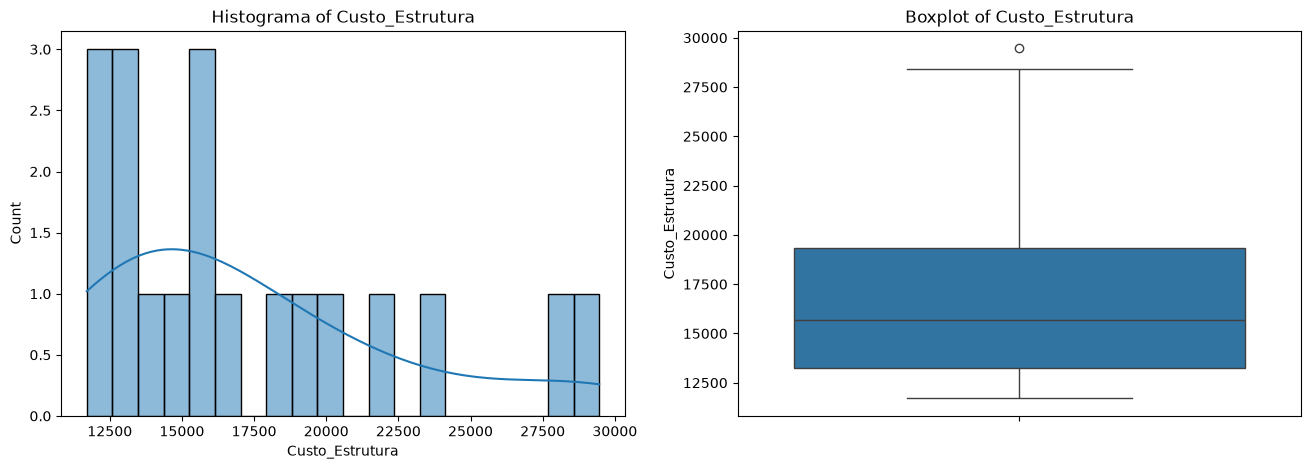

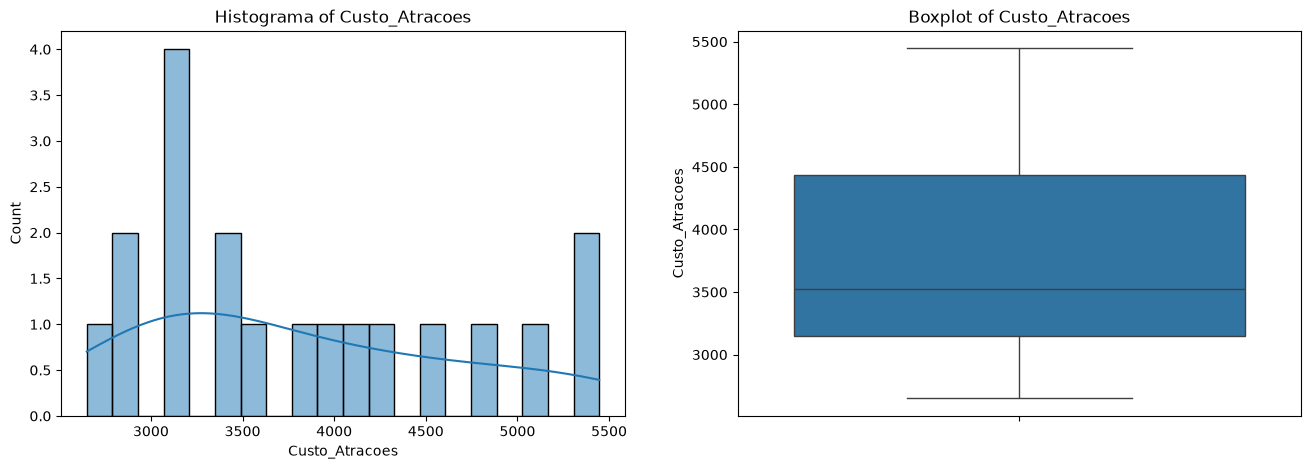

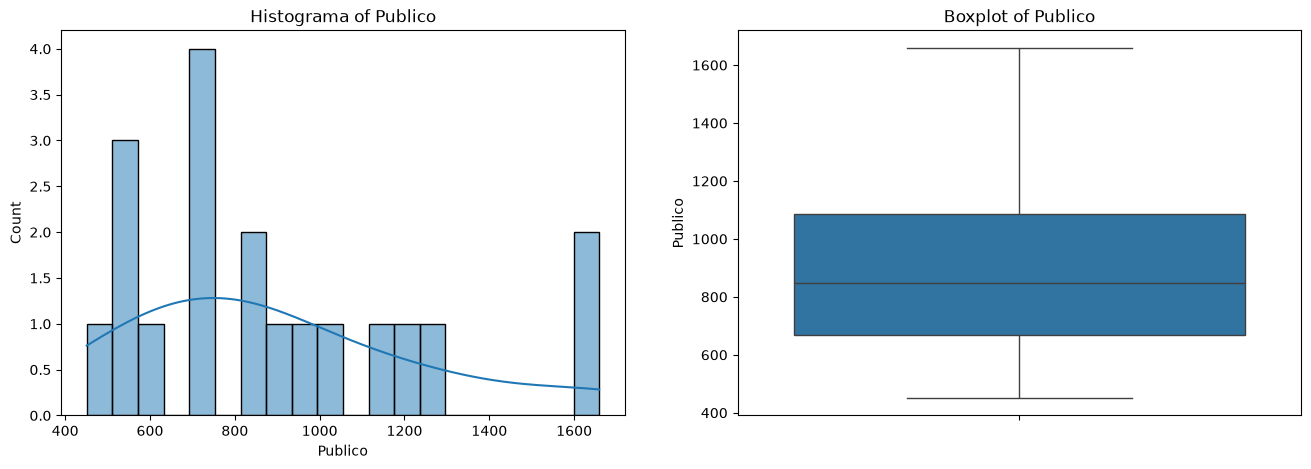

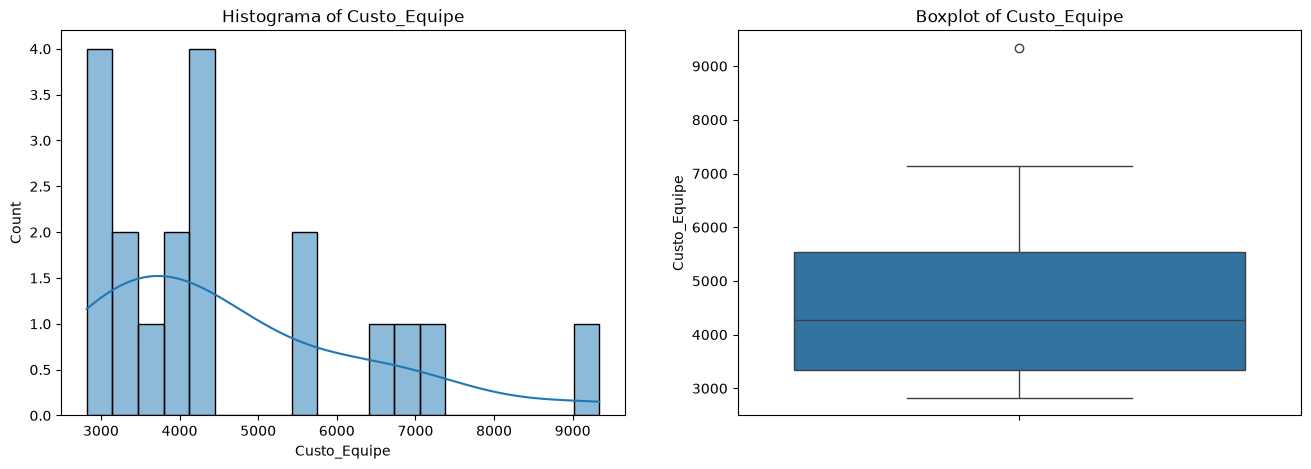

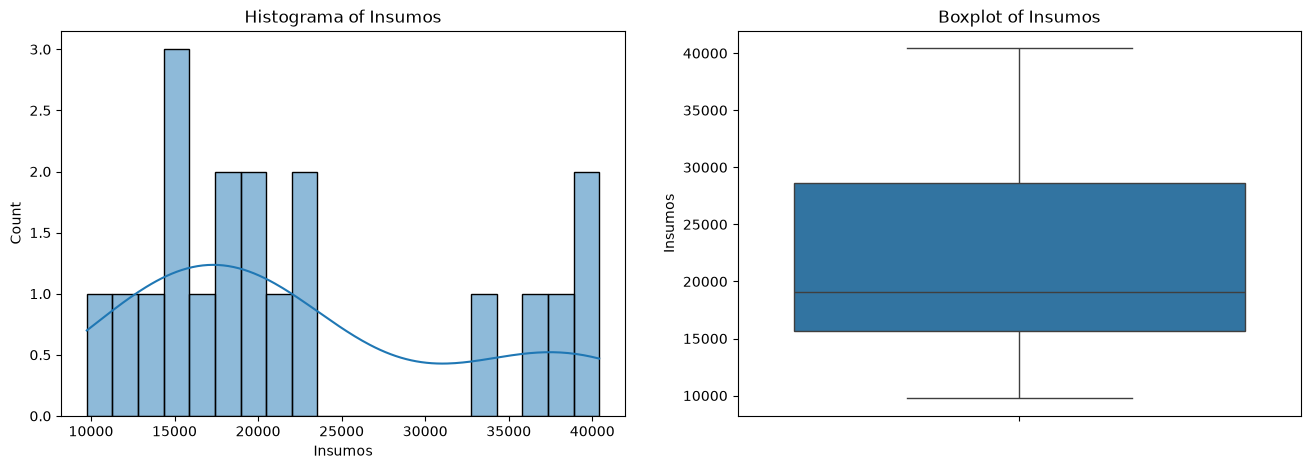

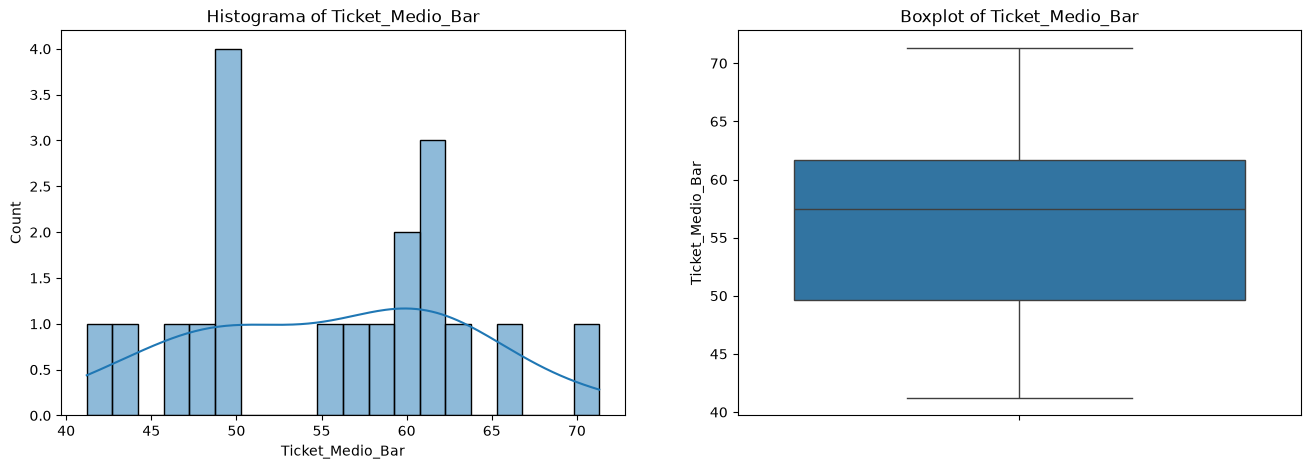

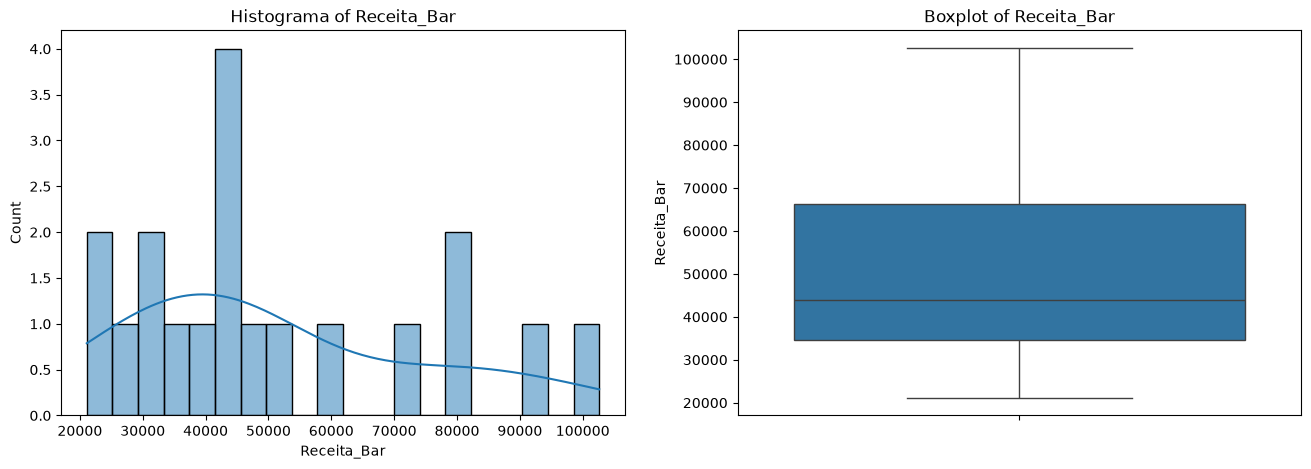

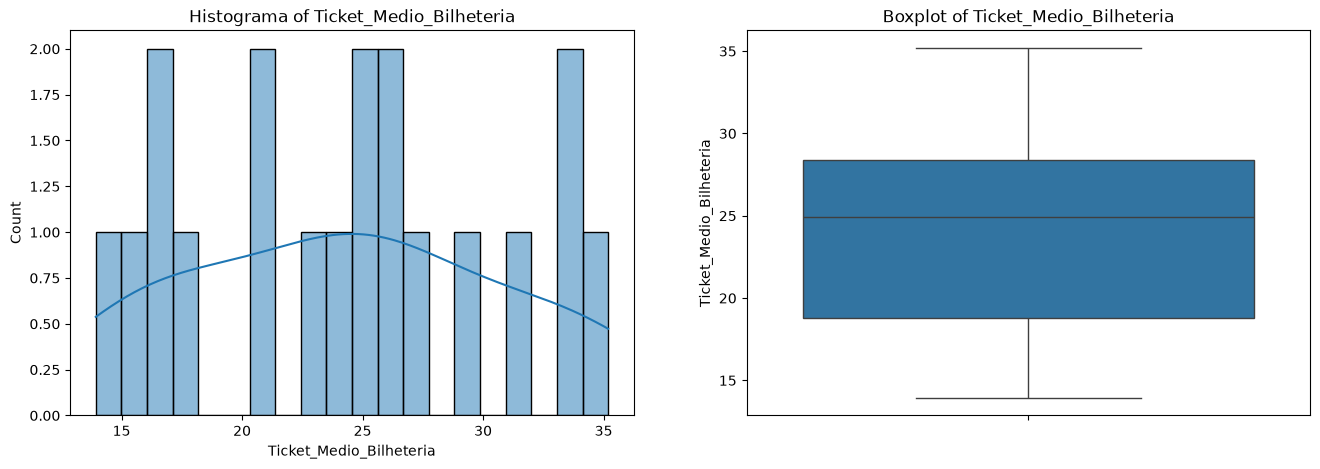

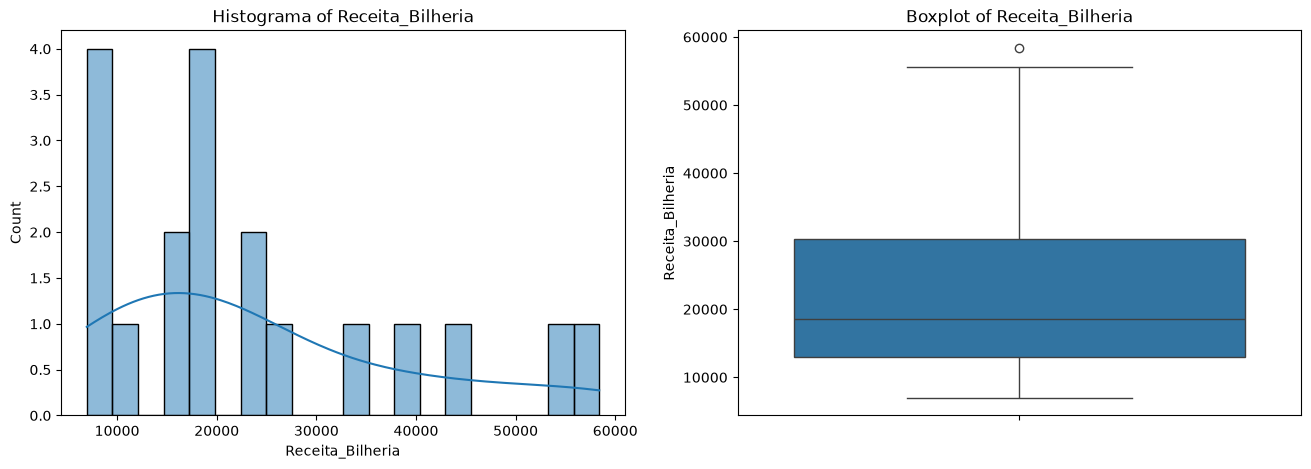

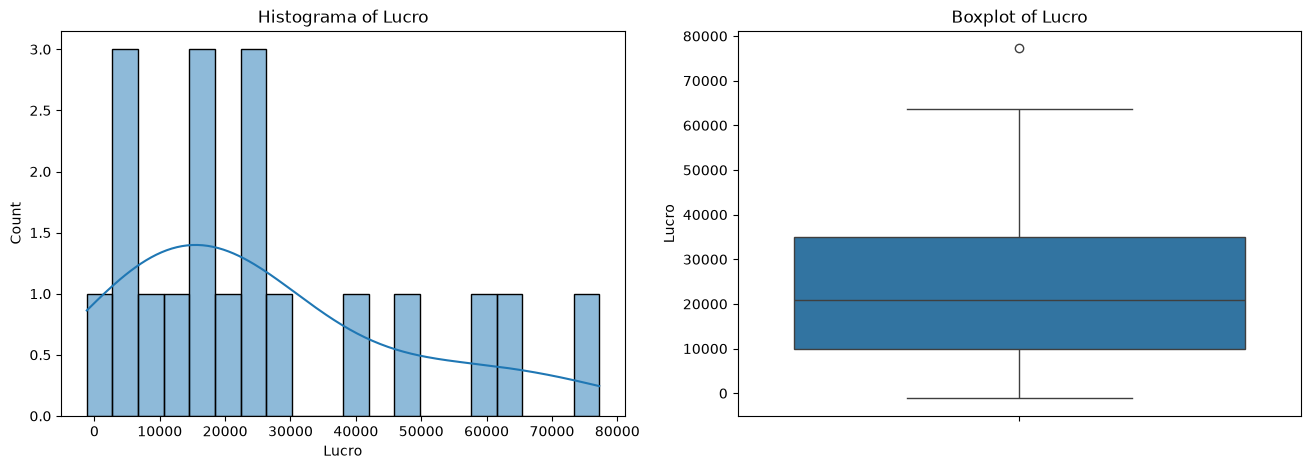

In [40]:
colunas = ['Custo_Estrutura',
 'Custo_Atracoes',
 'Publico',
 'Custo_Equipe',
 'Insumos',
 'Ticket_Medio_Bar',
 'Receita_Bar',
 'Ticket_Medio_Bilheteria',
 'Receita_Bilheria',
 'Lucro']

for col in (colunas):
    fig, ax = plt.subplots(1, 2, figsize=(16, 5))
    ax[0].set_title(f'Histograma of {col}')
    sns.histplot(data=df1, x=col, kde=True, alpha=0.5, bins=20, ax=ax[0])

    #mostra a distribuição e mediana. Os traços de fora é o intervalo existes
    #o quadrado colorido é a concentração e sua mediana
    sns.boxplot(y=col, data=df1)
    ax[1].set_title(f'Boxplot of {col}')

## Análise Bivariada

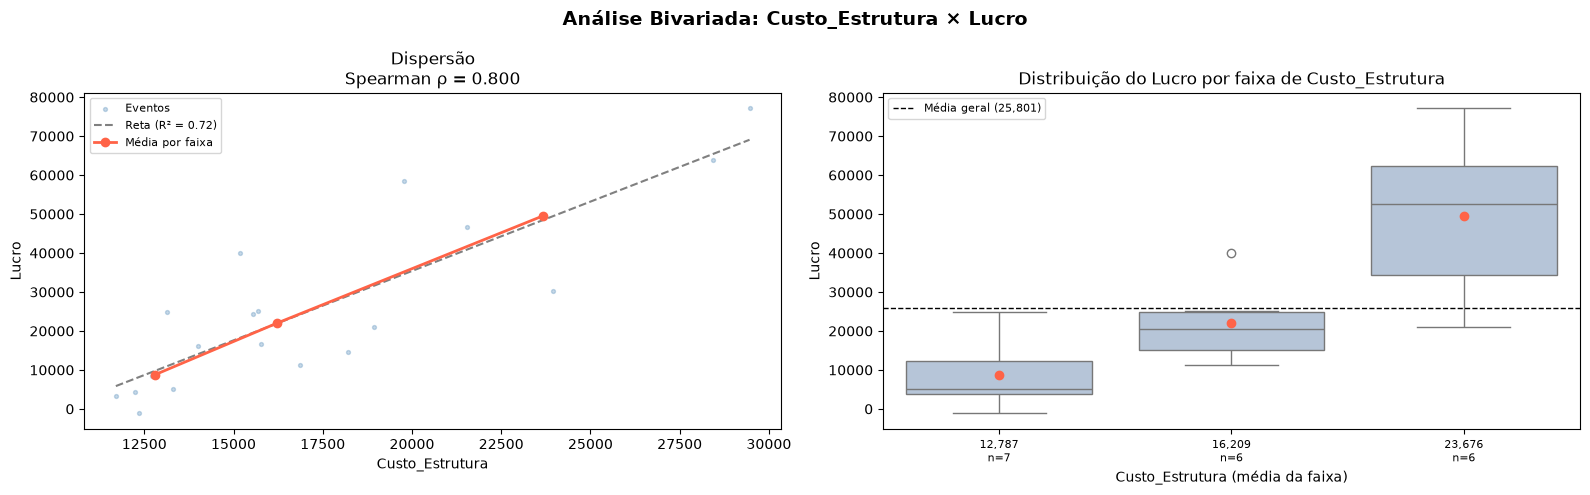

──────────────────────────────────────────────────────────────────────
  Custo_Estrutura
  Spearman ρ = 0.800  |  R² da reta = 0.724
──────────────────────────────────────────────────────────────────────



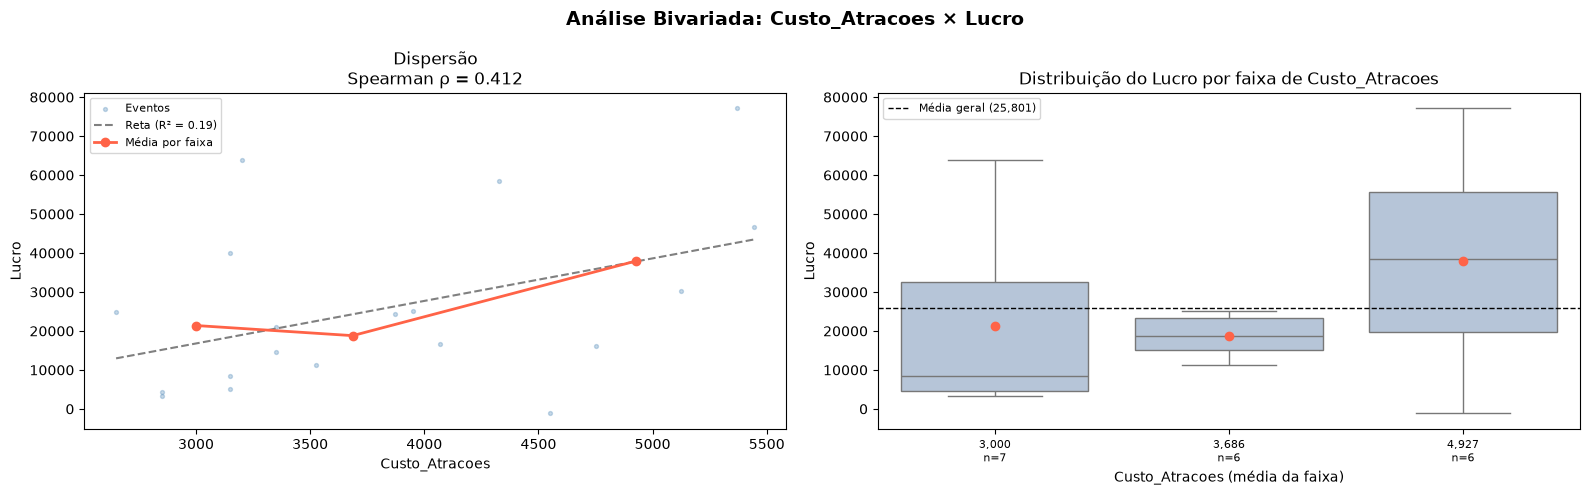

──────────────────────────────────────────────────────────────────────
  Custo_Atracoes
  Spearman ρ = 0.412  |  R² da reta = 0.190
──────────────────────────────────────────────────────────────────────



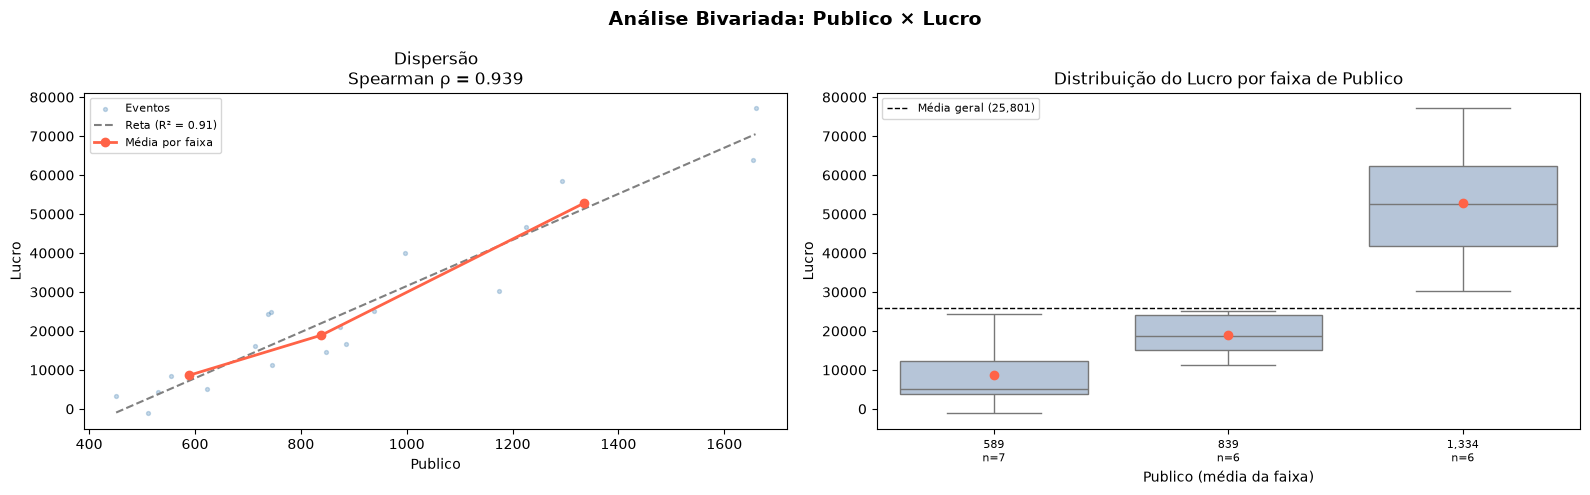

──────────────────────────────────────────────────────────────────────
  Publico
  Spearman ρ = 0.939  |  R² da reta = 0.912
──────────────────────────────────────────────────────────────────────



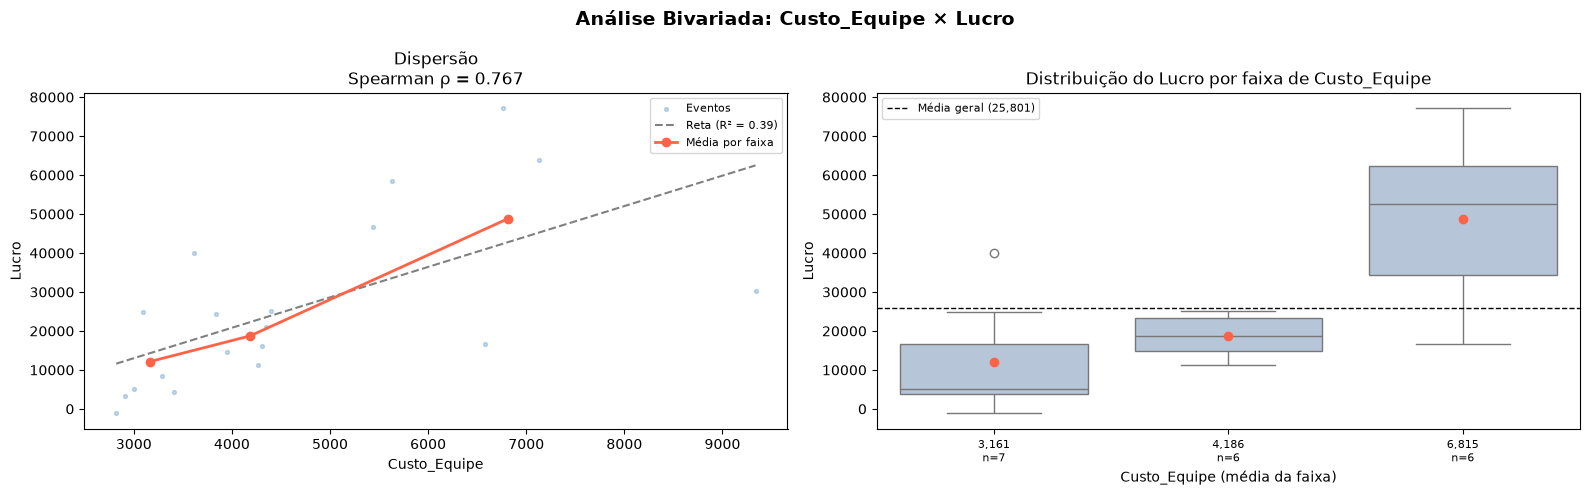

──────────────────────────────────────────────────────────────────────
  Custo_Equipe
  Spearman ρ = 0.767  |  R² da reta = 0.385
──────────────────────────────────────────────────────────────────────



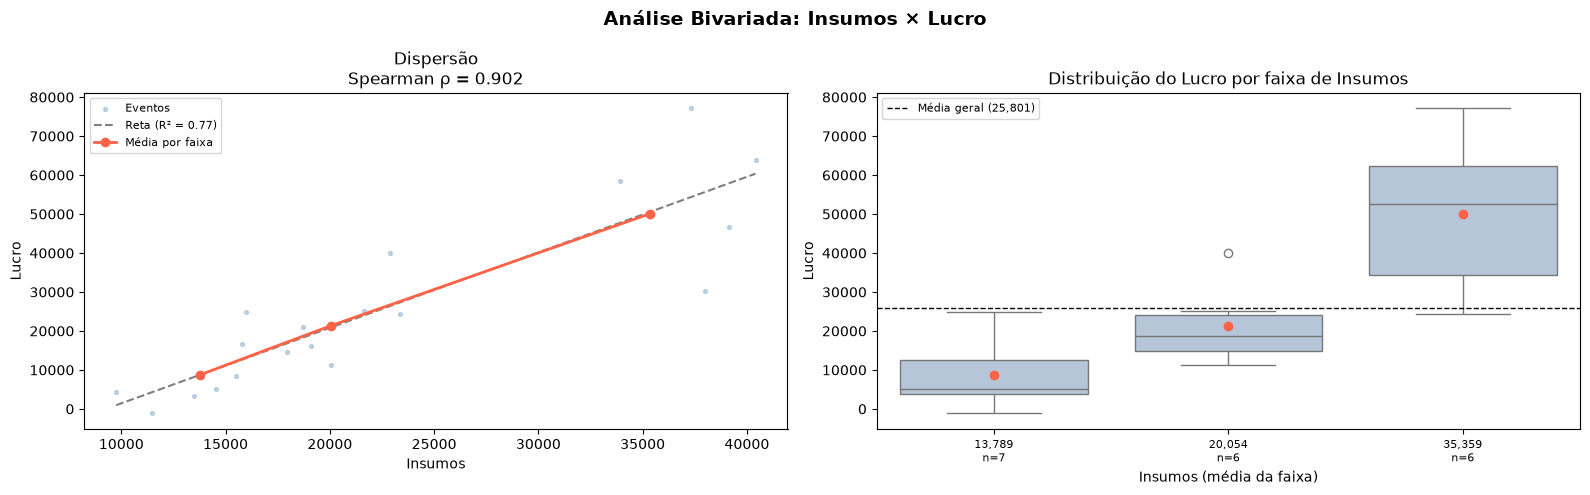

──────────────────────────────────────────────────────────────────────
  Insumos
  Spearman ρ = 0.902  |  R² da reta = 0.772
──────────────────────────────────────────────────────────────────────



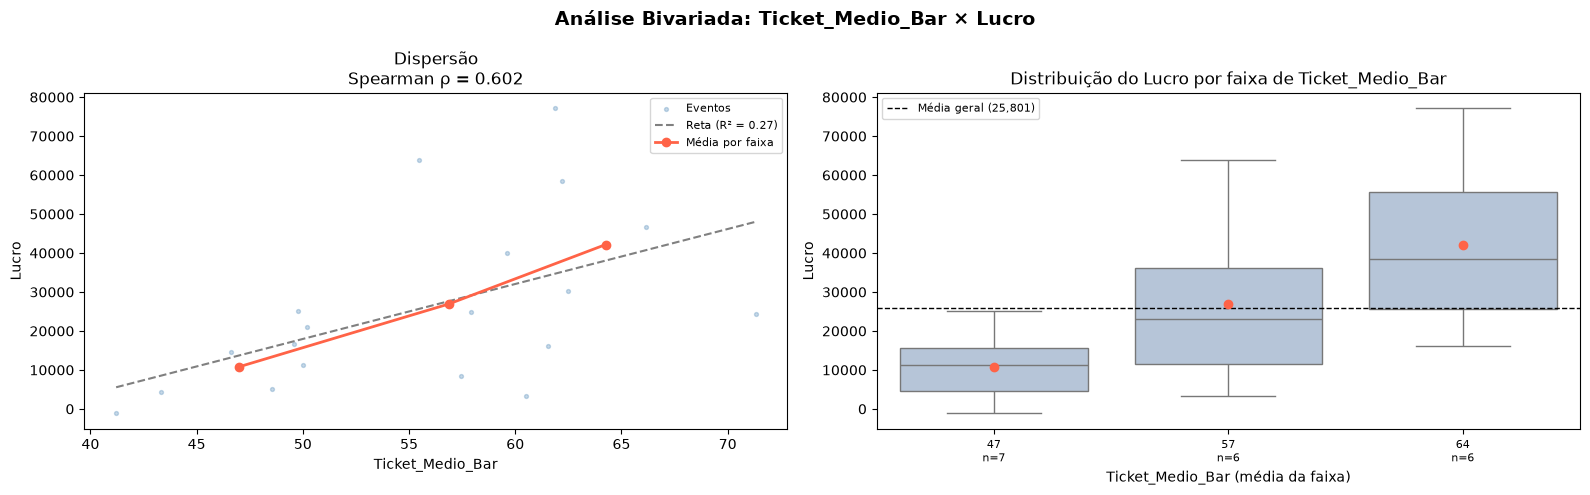

──────────────────────────────────────────────────────────────────────
  Ticket_Medio_Bar
  Spearman ρ = 0.602  |  R² da reta = 0.270
──────────────────────────────────────────────────────────────────────



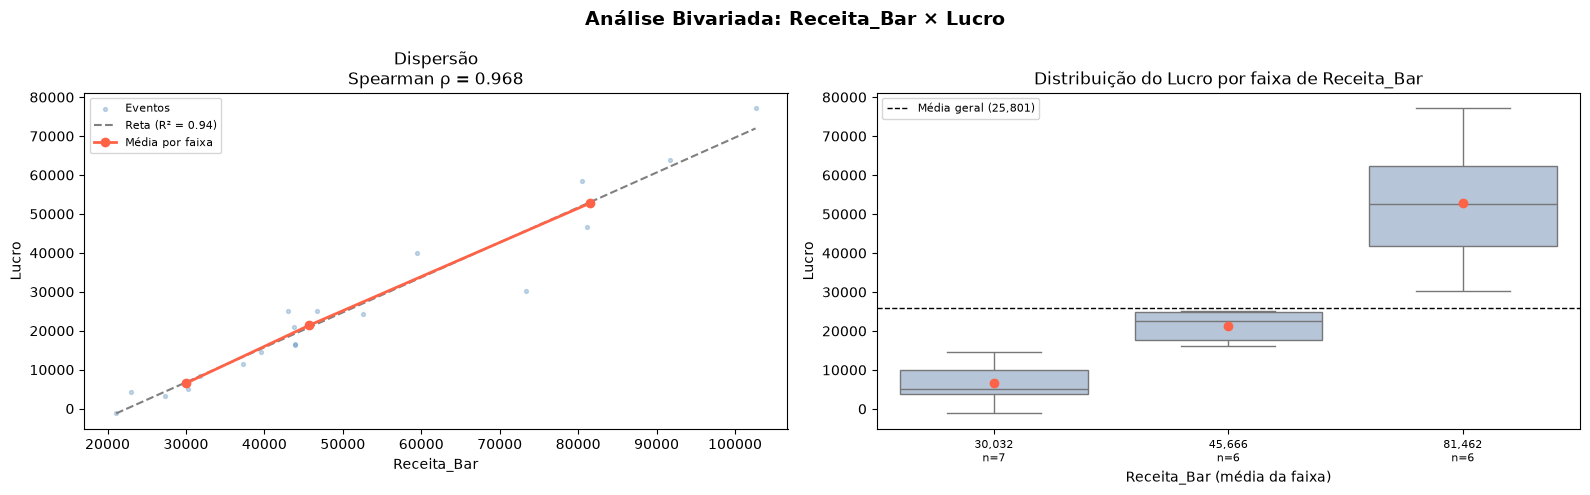

──────────────────────────────────────────────────────────────────────
  Receita_Bar
  Spearman ρ = 0.968  |  R² da reta = 0.943
──────────────────────────────────────────────────────────────────────



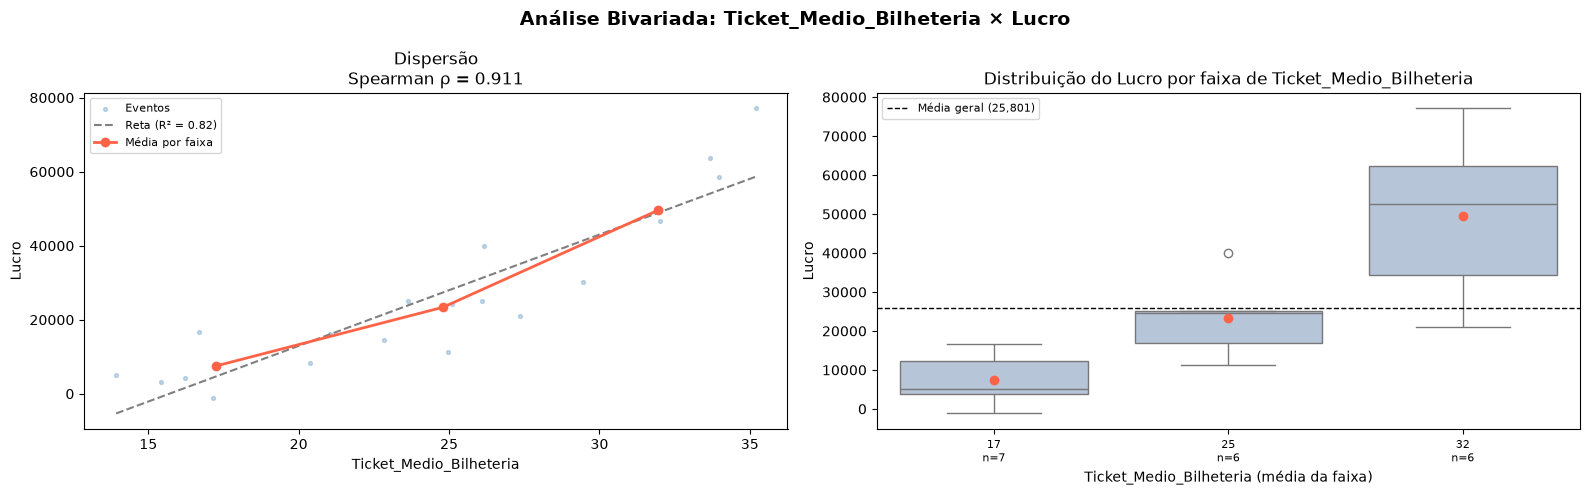

──────────────────────────────────────────────────────────────────────
  Ticket_Medio_Bilheteria
  Spearman ρ = 0.911  |  R² da reta = 0.816
──────────────────────────────────────────────────────────────────────



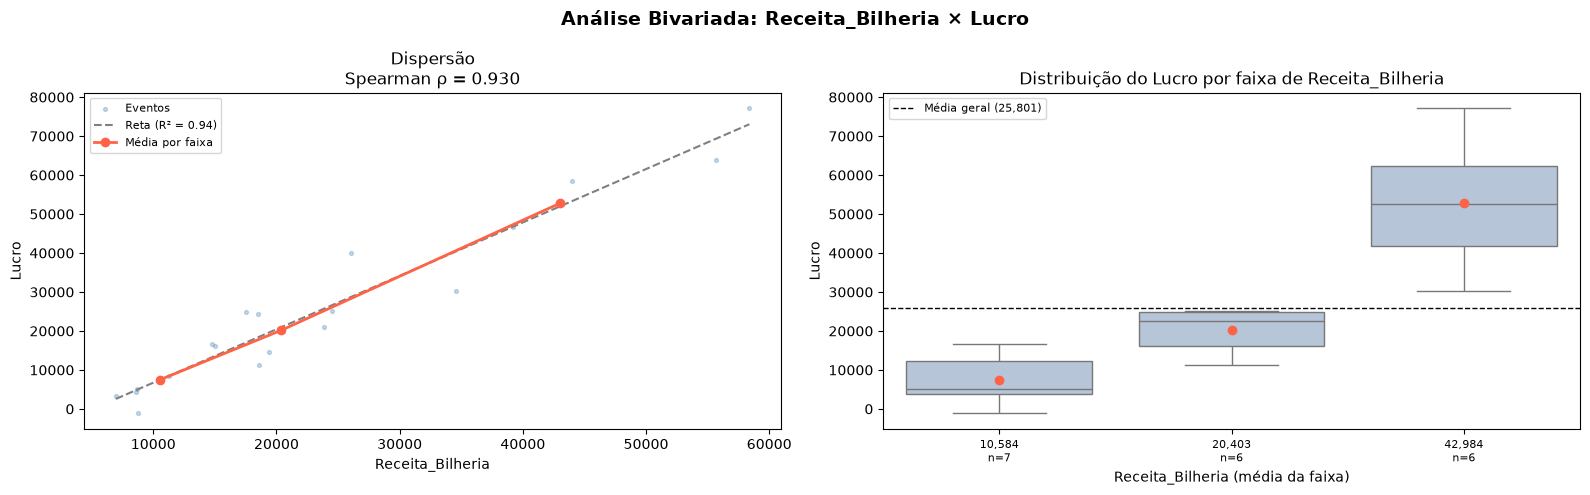

──────────────────────────────────────────────────────────────────────
  Receita_Bilheria
  Spearman ρ = 0.930  |  R² da reta = 0.936
──────────────────────────────────────────────────────────────────────



In [42]:
TARGET = 'Lucro'
colunas = ['Custo_Estrutura',
           'Custo_Atracoes',
           'Publico',
           'Custo_Equipe',
           'Insumos',
           'Ticket_Medio_Bar',
           'Receita_Bar',
           'Ticket_Medio_Bilheteria',
           'Receita_Bilheria']

# ==============================================================
# PARTE 1 — Configuração
# ==============================================================

media_geral = df1[TARGET].mean()

for col in colunas:
    dados = df1[[col, TARGET]].dropna().copy()

    # ==============================================================
    # --- Medidas de relação ---
    # ==============================================================

    spearman = dados[col].corr(dados[TARGET], method='spearman')   # relação que sobe/desce (reta ou curva)
    r2_reta  = dados[col].corr(dados[TARGET]) ** 2                 # quanto uma reta explica (0 a 1)

    # ==============================================================
    # --- Faixas: valores próprios (discreta) ou quantis (contínua) ---
    # ==============================================================

    if dados[col].nunique() <= 3:
        dados['faixa'] = dados[col].astype('category')   # cada valor vira uma faixa
    else:
        dados['faixa'] = pd.qcut(dados[col], q=3, duplicates='drop')   # 8 faixas com nº parecido de eventos

    resumo = (
        dados.groupby('faixa', observed=True)
        .agg(x_medio=(col, 'mean'), alvo_medio=(TARGET, 'mean'), N=(TARGET, 'size'))
    )
    rotulos = [f'{x:,.0f}\nn={n}' for x, n in zip(resumo['x_medio'], resumo['N'])]

    # ==============================================================
    # --- Reta ajustada ---
    # ==============================================================

    b, a = np.polyfit(dados[col], dados[TARGET], 1)
    xs   = np.array([dados[col].min(), dados[col].max()])

    # ==============================================================
    # --- Plots --- Estrutura
    # ==============================================================

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    fig.suptitle(f'Análise Bivariada: {col} × {TARGET}', fontsize=14, fontweight='bold')

    # ==============================================================
    # ── Plot 1: Dispersão + reta + média por faixa ──
    # ==============================================================

    axes[0].scatter(dados[col], dados[TARGET], s=8, alpha=0.3, color='steelblue', label='Eventos')
    axes[0].plot(xs, a + b * xs, linestyle='--', color='gray', label=f'Reta (R² = {r2_reta:.2f})')
    axes[0].plot(resumo['x_medio'], resumo['alvo_medio'], marker='o', color='tomato', lw=2,
                 label='Média por faixa')

    axes[0].set_title(f'Dispersão\nSpearman ρ = {spearman:.3f}')
    axes[0].set_xlabel(col)
    axes[0].set_ylabel(TARGET)
    axes[0].legend(fontsize=8)

    # ==============================================================
    # ── Plot 2: Boxplot do alvo por faixa ──
    # ==============================================================

    sns.boxplot(x=dados['faixa'].cat.codes, y=dados[TARGET], ax=axes[1],
                color='lightsteelblue', showmeans=True,
                meanprops=dict(marker='o', markerfacecolor='tomato', markeredgecolor='tomato'))
    axes[1].axhline(media_geral, color='black', linestyle='--', linewidth=1,
                    label=f'Média geral ({media_geral:,.0f})')

    axes[1].set_xticks(range(len(rotulos)))
    axes[1].set_xticklabels(rotulos, fontsize=8)
    axes[1].set_title(f'Distribuição do {TARGET} por faixa de {col}')
    axes[1].set_xlabel(f'{col} (média da faixa)')
    axes[1].set_ylabel(TARGET)
    axes[1].legend(fontsize=8)

    plt.tight_layout()
    plt.show()

    # ==============================================================
    # --- Resumo textual ---
    # ==============================================================

    print('─' * 70)
    print(f'  {col}')
    print(f'  Spearman ρ = {spearman:.3f}  |  R² da reta = {r2_reta:.3f}')
    print('─' * 70 + '\n')



# DEA - Data Envelopment Analisys

## Função DEA

In [47]:
# ==========================================================================
# DEA completo: inputs + CCR + BCC + escala (eventos)
# ==========================================================================

COL_ID = 'Evento_ID'

# --- 1. Colunas de input e output ------------------------------------------
df1['Receita_Total']         = df1['Receita_Bar'] + df1['Receita_Bilheria']
df1['Custo_Estrutura_Total'] = df1['Custo_Estrutura'] + df1['Custo_Equipe']

cols_inputs = ['Custo_Estrutura_Total', 'Custo_Atracoes', 'Insumos']
cols_output = ['Receita_Total']

# --- 2. Checagem dos dados antes de rodar ----------------------------------
def checar_dados(df_grupo, nome_grupo):
    """Confere zeros/negativos e se há DMUs suficientes (regra de Cooper)."""
    problemas = df_grupo[cols_inputs + cols_output] <= 0
    if problemas.any().any():
        for col in problemas.columns[problemas.any()]:
            eventos = df_grupo.loc[problemas[col], COL_ID].tolist()
            print(f'[{nome_grupo}] ATENÇÃO: {col} <= 0 em {eventos}')
    else:
        print(f'[{nome_grupo}] dados ok: nenhum zero ou negativo')

    n, m, s = len(df_grupo), len(cols_inputs), len(cols_output)
    minimo = max(m * s, 3 * (m + s))
    print(f'[{nome_grupo}] Cooper: {n} DMUs, mínimo {minimo} -> {"ok" if n >= minimo else "POUCAS DMUs"}')


# --- 3. Um modelo DEA (CCR, BCC, RNC ou RND) ------------------------------
def rodar_dea(df_grupo, retorno='CRS'):
    """Roda o DEA orientado a insumo.
    retorno: 'CRS' (CCR), 'VRS' (BCC), 'NIRS' (RNC) ou 'NDRS' (RND).
    Devolve (modelo, tabela com score, eficiência, peers, folgas, metas e economia)."""
    X = df_grupo[cols_inputs].to_numpy(dtype=float)
    Y = df_grupo[cols_output].to_numpy(dtype=float)
    eventos = df_grupo[COL_ID].tolist()

    modelo = fm(retorno, 'in')
    modelo.fit(X, Y)

    linhas = []
    for i, r in enumerate(modelo.result):
        meta = r.virtual_dmu.input                      # inputs-alvo: score x atual - folga
        linha = {
            'evento': eventos[i],
            'score': round(r.score, 3),
            # eficiência forte: score 1 e sem folga (tolerância por causa do ruído do solver)
            'eficiente': r.score >= 1 - 1e-6 and sum(r.x_slack) <= 1e-4 * X[i].sum(),
            'peers_pesos': {eventos[j]: round(w, 2) for j, w in enumerate(r.weights) if w > 1e-6},
        }
        for k, nome in enumerate(cols_inputs):
            linha[f'folga_{nome}'] = round(max(r.x_slack[k], 0))
            linha[f'meta_{nome}'] = round(meta[k])
            linha[f'reducao_%_{nome}'] = round((1 - meta[k] / X[i, k]) * 100, 1)

        # economia potencial: custo atual - custo-meta (soma dos inputs, em R$ por evento)
        custo_atual = X[i].sum()
        custo_meta  = meta.sum()
        linha['custo_atual'] = round(custo_atual)
        linha['custo_meta'] = round(custo_meta)
        linha['economia_potencial'] = round(max(custo_atual - custo_meta, 0))
        linha['economia_%'] = round(max(custo_atual - custo_meta, 0) / custo_atual * 100, 1)

        linhas.append(linha)

    tabela = pd.DataFrame(linhas).sort_values('score', ascending=False).reset_index(drop=True)
    return modelo, tabela


# --- 4. CCR x BCC: escala e diagnóstico ------------------------------------
def tipo_retorno(linha):
    if abs(linha['escala'] - 1) < 1e-3:
        return 'Constante'
    if abs(linha['RNC'] - linha['BCC']) < 1e-3:
        return 'Decrescente'      # RNC = BCC -> já passou do tamanho ideal
    return 'Crescente'            # RNC != BCC -> pequeno demais


def diagnostico(linha):
    if linha['CCR'] >= 0.999:
        return 'Eficiente'
    if linha['BCC'] >= 0.999:
        return 'Escala'
    return 'Gestão' if linha['escala'] >= linha['BCC'] else 'Escala'   # o componente menor é o problema principal


def analise_completa(df_grupo, nome_grupo):
    """Roda CCR, BCC e RNC e devolve um dicionário com todas as tabelas."""
    checar_dados(df_grupo, nome_grupo)
    _, df_ccr = rodar_dea(df_grupo, 'CRS')
    _, df_bcc = rodar_dea(df_grupo, 'VRS')
    _, df_rnc = rodar_dea(df_grupo, 'NIRS')

    comparacao = (df_ccr[['evento', 'score']].rename(columns={'score': 'CCR'})
                  .merge(df_bcc[['evento', 'score']].rename(columns={'score': 'BCC'}), on='evento')
                  .merge(df_rnc[['evento', 'score']].rename(columns={'score': 'RNC'}), on='evento'))
    comparacao['escala'] = (comparacao['CCR'] / comparacao['BCC']).round(3)
    comparacao['retorno'] = comparacao.apply(tipo_retorno, axis=1)
    comparacao['problema_principal'] = comparacao.apply(diagnostico, axis=1)
    comparacao = comparacao.sort_values('CCR', ascending=False).reset_index(drop=True)

    return {'ccr': df_ccr, 'bcc': df_bcc, 'comparacao': comparacao}


# --- 5. Rodando com todos os eventos ----------------------------------------
resultado = analise_completa(df1, 'Eventos')

resultado['comparacao']


[Eventos] dados ok: nenhum zero ou negativo
[Eventos] Cooper: 19 DMUs, mínimo 12 -> ok


,evento,CCR,BCC,RNC,escala,retorno,problema_principal
0,Q5,1.000,1.000,1.000,1.000,Constante,Eficiente
1,Q16,1.000,1.000,1.000,1.000,Constante,Eficiente
2,Q10,1.000,1.000,1.000,1.000,Constante,Eficiente
3,Q4,0.963,1.000,0.963,0.963,Crescente,Escala
4,Q14,0.910,0.916,0.910,0.993,Crescente,Gestão
5,Q6,0.878,1.000,0.878,0.878,Crescente,Escala
6,Q12,0.863,0.984,0.863,0.877,Crescente,Escala
7,Q7,0.838,0.933,0.838,0.898,Crescente,Escala
8,Q15,0.785,0.870,0.785,0.902,Crescente,Gestão
9,Q13,0.780,0.894,0.780,0.872,Crescente,Escala


In [48]:
resultado['ccr']   # score, peers, folgas, metas e economia (CCR)

,evento,score,eficiente,peers_pesos,folga_Custo_Estrutura_Total,meta_Custo_Estrutura_Total,reducao_%_Custo_Estrutura_Total,folga_Custo_Atracoes,meta_Custo_Atracoes,reducao_%_Custo_Atracoes,folga_Insumos,meta_Insumos,reducao_%_Insumos,custo_atual,custo_meta,economia_potencial,economia_%
0,Q5,1.000,True,{'Q5': 1.0},0,35559,-0.0,0,3200,0.0,0,40413,-0.0,79172,79172,0,0.0
1,Q16,1.000,True,{'Q16': 1.0},0,25405,-0.0,0,4325,-0.0,0,33898,-0.0,63628,63628,0,0.0
2,Q10,1.000,True,{'Q10': 1.0},0,36218,0.0,0,5368,-0.0,0,37322,-0.0,78907,78907,0,0.0
3,Q4,0.963,False,"{'Q16': 0.43, 'Q10': 0.19}",0,18103,3.7,106,2927,7.1,0,22012,3.7,44816,43042,1774,4.0
4,Q14,0.910,False,{'Q16': 0.97},0,24556,9.0,776,4180,23.2,2865,32765,16.3,71573,61502,10071,14.1
5,Q6,0.878,False,{'Q10': 0.38},623,13632,16.0,306,2020,23.8,0,14047,12.2,34883,29700,5184,14.9
6,Q12,0.863,False,{'Q10': 0.36},6074,13205,40.9,1554,1957,51.9,0,13607,13.7,42190,28769,13421,31.8
7,Q7,0.838,False,{'Q10': 0.42},4270,15232,34.5,550,2258,32.6,0,15696,16.2,45349,33185,12164,26.8
8,Q15,0.785,False,"{'Q16': 0.09, 'Q10': 0.37}",0,15766,21.5,711,2389,39.5,0,16966,21.5,45671,35122,10550,23.1
9,Q13,0.780,False,"{'Q16': 0.34, 'Q10': 0.18}",0,15110,22.0,585,2433,37.1,0,18233,22.0,46627,35775,10851,23.3


In [49]:
resultado['bcc']   # o mesmo pelo BCC


,evento,score,eficiente,peers_pesos,folga_Custo_Estrutura_Total,meta_Custo_Estrutura_Total,reducao_%_Custo_Estrutura_Total,folga_Custo_Atracoes,meta_Custo_Atracoes,reducao_%_Custo_Atracoes,folga_Insumos,meta_Insumos,reducao_%_Insumos,custo_atual,custo_meta,economia_potencial,economia_%
0,Q1,1.000,True,{'Q1': 1.0},0,14613,0.0,0,2850,0.0,0,13485,-0.0,30948,30948,0,0.0
1,Q9,1.000,True,{'Q9': 1.0},0,15178,0.0,0,4550,0.0,0,11458,-0.0,31185,31185,0,0.0
2,Q19,1.000,True,{'Q19': 1.0},0,15659,0.0,0,2850,0.0,0,9751,-0.0,28260,28260,0,0.0
3,Q6,1.000,True,{'Q6': 1.0},0,16235,0.0,0,2650,0.0,0,15999,-0.0,34883,34883,0,0.0
4,Q5,1.000,True,{'Q5': 1.0},0,35559,-0.0,0,3200,0.0,0,40413,-0.0,79172,79172,0,0.0
5,Q10,1.000,True,{'Q10': 1.0},0,36218,0.0,0,5368,0.0,0,37322,0.0,78907,78907,0,0.0
6,Q4,1.000,True,{'Q4': 1.0},0,18803,0.0,0,3150,0.0,0,22863,0.0,44816,44816,0,0.0
7,Q16,1.000,True,{'Q16': 1.0},0,25405,-0.0,0,4325,-0.0,0,33898,-0.0,63628,63628,0,0.0
8,Q12,0.984,False,"{'Q19': 0.79, 'Q10': 0.21}",2029,19962,10.7,628,3377,17.0,0,15522,1.6,42190,38861,3330,7.9
9,Q2,0.947,False,"{'Q1': 0.66, 'Q6': 0.34}",0,15159,5.3,199,2783,11.7,357,14330,7.6,34678,32271,2407,6.9


## Configuração do modelo e checagem dos dados

**Modelo escolhido:** DEA orientado a insumo, ou seja, a pergunta é *"quanto cada evento poderia gastar a menos e ainda gerar a mesma receita?"*

| Papel | Variável | Por quê |
|---|---|---|
| Input | `Custo_Estrutura_Total` (estrutura + equipe) | recurso gasto para montar o evento |
| Input | `Custo_Atracoes` | recurso gasto com as atrações |
| Input | `Insumos` | recurso gasto com produtos (bar etc.) |
| Output | `Receita_Total` (bar + bilheteria) | o que o evento gera |

- **Por que receita e não lucro:** o lucro pode ser negativo (o evento Q9 teve prejuízo de R$ 1.165), e o DEA não aceita valores negativos. Além disso, o lucro já desconta os custos, que estão nos inputs, e o custo seria contado duas vezes.
- **Zeros e negativos:** nenhum. Todos os 19 eventos têm valores positivos em todas as variáveis.
- **Regra de Cooper:** com 3 inputs e 1 output, o mínimo recomendado é max{3 × 1, 3 × (3 + 1)} = **12 DMUs**. Temos **19**, então o modelo tem eventos suficientes para diferenciar quem é eficiente de quem não é.


## Tabela CCR: eficiência total

O **CCR** (retornos constantes de escala, CRS) compara **todos os eventos com todos**, como se o tamanho não importasse. Ele mede a **eficiência total**: gestão + tamanho do evento.

### O que cada coluna significa

Exemplo usado: **Q6** (score 0,878).

| Coluna | O que é | Como ler (Q6) |
|---|---|---|
| `score` | eficiência de 0 a 1. **1 = eficiente**; abaixo de 1, é a fração dos inputs que bastaria para gerar a mesma receita | 0,878: o Q6 poderia ter gerado os mesmos R$ 60.599 de receita usando só **87,8%** do que gastou |
| `eficiente` | `True` só se score = 1 **e** não sobra nenhuma folga (eficiência "forte") | False |
| `peers_pesos` | os eventos eficientes que servem de **referência** (benchmark) e o peso de cada um | `{'Q10': 0.38}`: o Q6 deveria se parecer com "38% do evento Q10" |
| `folga_<input>` | redução **extra**, além do corte proporcional do score, que ainda seria possível naquele input | folga de R$ 623 em estrutura e R$ 306 em atrações |
| `meta_<input>` | quanto o evento **deveria** gastar naquele input para ser eficiente (atual × score − folga) | estrutura: de R$ 16.235 para **R$ 13.632** |
| `reducao_%_<input>` | o corte necessário, em %, naquele input | estrutura −16,0%, atrações −23,8%, insumos −12,2% |
| `custo_atual` | soma dos 3 inputs hoje | R$ 34.883 |
| `custo_meta` | soma das metas | R$ 29.700 |
| `economia_potencial` | custo atual − custo meta, em R$ | **R$ 5.184** |
| `economia_%` | a economia como % do custo atual | 14,9% |

> Valores como `-0.0` são só arredondamento do solver: na prática, zero.

### Resultados

- **3 eventos eficientes:** **Q5, Q10 e Q16**. Os três estão entre os maiores (1.294 a 1.659 pessoas de público).
- **Eficiência média: 0,793.** Em média, os eventos poderiam gerar a mesma receita gastando cerca de 21% menos.
- **Menos eficientes:** Q1 (0,589), Q9 (0,605), Q3 (0,620) e Q2 (0,644), todos eventos pequenos (451 a 623 pessoas).
- **O Q10 é a referência de quase todos:** aparece em 15 dos 16 eventos ineficientes. É o evento que mais gera receita por real gasto (**R$ 2,04 de receita para cada R$ 1 de custo**).
- **As atrações são o input com mais folga:** aparecem com folga em 15 eventos, e as reduções sugeridas vão até 78% (Q9). Ou seja, o custo de atrações é o mais desproporcional à receita gerada. Os insumos quase nunca têm folga (só no Q14).
- **Economia potencial total: R$ 203.640**, ou 22,2% dos R$ 918.636 gastos pelos 19 eventos. Esse número é **otimista**: ele exige que um evento pequeno tenha a produtividade dos maiores, o que nem sempre é possível. A tabela BCC dá a versão realista.


## Tabela BCC: eficiência de gestão

O **BCC** (retornos variáveis de escala, VRS) compara cada evento **só com eventos de porte parecido**. Ele tira o efeito do tamanho e mede só a **eficiência de gestão**: dado o tamanho do evento, os custos foram bem administrados?

As colunas são as mesmas da tabela CCR e se leem do mesmo jeito.

### Resultados

- **8 eventos eficientes:** Q1, Q4, Q5, Q6, Q9, Q10, Q16 e Q19, contra só 3 no CCR. É esperado: comparando só com "vizinhos de tamanho", mais eventos ficam na fronteira.
- **Eficiência média: 0,932.** Descontado o tamanho, a gestão de custos está boa na média: o desperdício é de cerca de 7%.
- **Menos eficientes:**
  - **Q17 (0,724):** um evento grande (1.174 pessoas), mas com o maior custo de equipe da base (R$ 9.337). É o caso com a maior economia possível: **R$ 21.081 (27,6%)**.
  - **Q18 (0,761):** poderia cortar 23,9% em todos os inputs, R$ 10.692.
- **Referências (peers) mudam:** em vez do Q10 para todo mundo, os benchmarks passam a ser eventos de porte médio, principalmente o **Q6** e o **Q4**. Eles são modelos mais realistas para eventos desse tamanho.
- **Economia potencial total: R$ 84.772** (9,2% do custo). Essa é a economia **alcançável só com gestão**, sem mudar o tamanho do evento.

### Atenção: eficiente no BCC não quer dizer lucrativo
O **Q9 teve prejuízo** (−R$ 1.165) e mesmo assim saiu com BCC = 1. Isso acontece porque ele é o evento com a **menor receita** da base. Não existe nenhum evento ou combinação de eventos menor para compará-lo, então ele fica eficiente "por falta de concorrente". O mesmo vale para o Q1 e o Q19, os menores em alguns custos.

O BCC = 1 desses eventos pequenos deve ser lido com cuidado. A tabela de comparação mostra que o problema deles é o **tamanho**.


## Comparação CCR × BCC: escala e diagnóstico

Essa tabela junta os dois modelos para responder: **a ineficiência vem da gestão ou do tamanho do evento?**

### O que cada coluna significa

| Coluna | O que é | Como ler |
|---|---|---|
| `CCR` | eficiência total (gestão + tamanho) | 1 = eficiente em tudo |
| `BCC` | eficiência de gestão (descontado o tamanho) | 1 = bem gerido para o seu porte |
| `RNC` | eficiência com retornos não crescentes (NIRS); serve só para descobrir o tipo de retorno | comparado com CCR e BCC |
| `escala` | **CCR ÷ BCC**: o quanto o tamanho do evento atrapalha | 1 = tamanho ideal; 0,6 = o tamanho tira 40% da eficiência |
| `retorno` | **Crescente**: o evento é pequeno demais, crescer aumentaria a eficiência. **Decrescente**: grande demais. **Constante**: tamanho ideal | regra: RNC = BCC → decrescente; RNC ≠ BCC → crescente |
| `problema_principal` | qual componente é pior: **Escala** (escala < BCC) ou **Gestão** (BCC < escala) | diz onde agir primeiro |

**Exemplo, o Q1:** CCR 0,589 e BCC 1,000. A gestão está perfeita para o porte dele, mas o tamanho reduz a eficiência a 0,589 (escala = 0,589 ÷ 1,000). Retorno **crescente**: o evento é pequeno demais para a estrutura de custos que tem.

### Resultados

- **Retorno de escala:** 16 eventos com retorno **crescente**, 3 com retorno **constante** (Q5, Q10, Q16) e **nenhum decrescente**. Nenhum evento é grande demais; todos os ineficientes estão **abaixo** do tamanho ideal.
- **Problema principal:**

| Diagnóstico | Eventos | Quantos |
|---|---|---|
| Eficiente | Q5, Q10, Q16 | 3 |
| Escala | Q1, Q2, Q3, Q4, Q6, Q7, Q9, Q11, Q12, Q13, Q19 | 11 |
| Gestão | Q8, Q14, Q15, Q17, Q18 | 5 |

- **A escala é o problema dominante:** a eficiência de escala média é 0,852, mais baixa que a de gestão (0,932). Os piores casos de escala são os eventos menores: Q1 (0,589), Q9 (0,605), Q3 (0,671) e Q2 (0,680), todos com 450 a 620 pessoas.
- **A eficiência acompanha o tamanho do público:** a correlação de Spearman entre CCR e público é **0,84**, e entre CCR e lucro, **0,88**. Quanto maior o evento, mais eficiente e mais lucrativo.

**Por que isso acontece:** parte dos custos é **fixa**. A estrutura e as atrações custam quase o mesmo para 500 ou para 1.000 pessoas. Num evento grande esse custo é dividido por mais público e mais receita. Num evento pequeno, pesa muito mais.


## Conclusões

1. **O tamanho do evento é o principal fator de eficiência.** 11 dos 16 eventos ineficientes têm problema de **escala**, todos com retorno crescente. Eventos com menos de ~650 pessoas (Q1, Q2, Q3, Q9, Q19) não diluem os custos fixos de estrutura e atrações. Caminhos: **aumentar o público** desses formatos ou **montar uma estrutura menor**, proporcional ao público esperado.

2. **O custo de atrações é o mais desproporcional.** Foi o input com folga na maioria dos eventos. Vale revisar o cachê das atrações em relação ao público que elas trazem.

3. **Cinco eventos têm problema de gestão:** Q17, Q18, Q14, Q15 e Q8. O destaque é o **Q17**: um evento grande com o maior custo de equipe da base, e uma economia possível de R$ 21 mil só com gestão.

4. **Referências para copiar:**
   - **Q10:** o mais produtivo (R$ 2,04 de receita por R$ 1 de custo). É o modelo para eventos grandes.
   - **Q6 e Q4:** os modelos para eventos de porte médio, segundo o BCC.

5. **Economia possível:**
   - **R$ 84.772 (9,2%):** só com melhor gestão, mantendo o tamanho dos eventos (BCC).
   - **R$ 203.640 (22,2%):** se todos os eventos tivessem a escala ideal (CCR). É o teto teórico.

### Limitações
- **Eficiência relativa:** o DEA compara os eventos entre si. "Eficiente" quer dizer "o melhor desta base", não o melhor possível.
- **Inputs correlacionados:** com 19 eventos, cada evento pesa muito no resultado, e os inputs são muito correlacionados entre si (estrutura × insumos: 0,90).
- **BCC = 1 nos eventos menores** (Q1, Q9, Q19) pode ser efeito da falta de eventos comparáveis, e não boa gestão. O Q9 teve prejuízo.
- **Há custos fora do modelo:** o lucro não é exatamente receita − os 4 custos (a diferença chega a R$ 4.869 em um evento).
